# 01 · RQ1: How accurate are path claims and dependency rules?

We check every path claim against the file tree at the **snapshot** (the last commit before the dataset's scan date), compare context files with READMEs, and use the manual checks **R1** (missing claims) and **R2** (found claims) to estimate how many missing claims are real errors.

Uses: `data/processed/path_claims.csv`, `dependency_rules.csv`, `context_files.csv`, and the manual-check sheets `manual_review/R1`, `R2`.

In [1]:
import os, sys; sys.path.insert(0, '../src' if os.path.basename(os.getcwd()) == 'notebooks' else 'src')
from analysis_helpers import *   # moves to the package root and loads helpers
claims = load('path_claims')
snap = claims[claims.in_file_at_snapshot].copy()          # claims still in the file at the snapshot
snap['missing'] = ~snap.found_at_snapshot
N = {}

## 1 · How many path claims?

In [2]:
g = snap.groupby('document')
per_project = snap.groupby(['document', 'repo']).size()
t = pd.DataFrame({'claims': g.size(), 'projects': g.repo.nunique(), 'median claims per project': per_project.groupby('document').median()})
N['claims'] = t.claims.to_dict(); N['projects'] = t.projects.to_dict()
t

,claims,projects,median claims per project
document,,,
context_file,41090,3227,9.0
readme,1857,521,1.0


## 2 · Raw missing rate

A claim is *missing* if its path is not in the file tree at the snapshot, neither from the root nor as the end of a longer path (*lenient matching*). Missing is not the same as wrong: the extractor also picks up example paths, paths in the user's own project, and build outputs.

In [3]:
raw = g.missing.agg(['sum', 'mean']).rename(columns={'sum': 'missing', 'mean': 'missing rate'})
proj_any = snap.groupby(['document', 'repo']).missing.any().groupby('document').mean().rename('projects with >= 1 missing (raw)')
N['missing'] = raw.missing.to_dict(); N['missing_rate'] = raw['missing rate'].to_dict()
raw.join(proj_any).style.format({'missing rate': '{:.1%}', 'projects with >= 1 missing (raw)': '{:.0%}'})

,missing,missing rate,projects with >= 1 missing (raw)
document,,,
context_file,2182,5.3%,28%
readme,226,12.2%,26%


## 3 · Manual check R1: which missing claims are real errors?

We labelled 300 missing claims (180 from context files, 120 from READMEs). Two LLM labellers labelled each claim independently, a third pass settled disagreements, and one author reviewed the labels (`final_label`). The share of real errors (`WRONG_PATH`) is the checker's **precision**.

In [4]:
R1 = review_labels('R1_missing_path_claims')
R1['wrong'] = R1.label == 'WRONG_PATH'
pd.crosstab(R1.label, R1.document, margins=True)                       # Table V

R1_missing_path_claims: 300 items


document,context_file,readme,All
label,,,
GENERATED_OR_IGNORED,13,9,22
NOT_REPO_PATH,53,65,118
PARSE_ERROR,18,2,20
PLACEHOLDER_OR_EXAMPLE,20,9,29
WRONG_PATH,76,35,111
All,180,120,300


In [5]:
prec = {}
for d, x in R1.groupby('document'):
    k, n = int(x.wrong.sum()), len(x); lo, hi = wilson(k, n)
    prec[d] = dict(k=k, n=n, p=k / n, lo=lo, hi=hi)
pd.DataFrame(prec).T.style.format({'p': '{:.2f}', 'lo': '{:.2f}', 'hi': '{:.2f}'})

,k,n,p,lo,hi
context_file,76.000000,180.000000,0.42,0.35,0.50
readme,35.000000,120.000000,0.29,0.22,0.38


**Estimated real error rate** = raw missing rate × precision (the Wilson interval of the precision is carried over).

In [6]:
est = {}
for d in prec:
    r = N['missing_rate'][d]
    est[d] = dict(raw=r, estimate=r * prec[d]['p'], low=r * prec[d]['lo'], high=r * prec[d]['hi'])
N['estimated_error_rate'] = est
pd.DataFrame(est).T.style.format('{:.1%}')

,raw,estimate,low,high
context_file,5.3%,2.2%,1.9%,2.6%
readme,12.2%,3.5%,2.7%,4.6%


## 4 · Wrong from the start, or stale later?

Each missing claim either **never existed** while it was in the file, or **existed when written and was removed later** (stale). Precision differs a lot between the two, so we weight by it.

In [7]:
by_hist = R1.groupby(['document', 'history']).wrong.agg(['sum', 'size', 'mean'])
comp = snap[snap.missing].groupby(['document', 'history_outcome']).size()
ctx = 'context_file'
real_never = comp[(ctx, 'never_valid')] * by_hist.loc[(ctx, 'never_valid'), 'mean']
real_stale = comp[(ctx, 'stale_unfixed')] * by_hist.loc[(ctx, 'stale_unfixed'), 'mean']
N['real_errors_share_never_valid'] = real_never / (real_never + real_stale)
print(comp.to_string()); print()
print(by_hist.to_string()); print()
print(f'context files: {pct(comp[(ctx, "never_valid")] / comp[ctx].sum(), 0)} of missing paths never existed (raw); '
      f'{pct(N["real_errors_share_never_valid"], 0)} of estimated real errors')

document      history_outcome
context_file  never_valid        1737
              stale_unfixed       445
readme        never_valid         214
              stale_unfixed        12

                            sum  size      mean
document     history                           
context_file never_valid     46   148  0.310811
             stale_unfixed   30    32  0.937500
readme       never_valid     29   113  0.256637
             stale_unfixed    6     7  0.857143

context files: 80% of missing paths never existed (raw); 56% of estimated real errors


## 5 · Manual check R2: does lenient matching accept wrong claims?

In [8]:
R2 = review_labels('R2_found_path_claims')
N['found_check'] = R2.label.value_counts().to_dict()
pd.crosstab(R2.label, R2.match_type, margins=True)

R2_found_path_claims: 100 items


match_type,exact,suffix,All
label,,,
CORRECT,50,49,99
WRONG_MATCH,0,1,1
All,50,50,100


## 6 · Context files vs. READMEs in the same projects

In [9]:
both = snap.groupby(['repo', 'document']).missing.agg(['sum', 'size']).unstack().dropna()
paired = {d: both[('sum', d)].sum() / both[('size', d)].sum() for d in ['context_file', 'readme']}
N['paired'] = dict(projects=len(both), **{f'{d}_raw': v for d, v in paired.items()}, **{f'{d}_adjusted': v * prec[d]['p'] for d, v in paired.items()})
pd.Series(N['paired'])

projects                 453.000000
context_file_raw           0.048626
readme_raw                 0.111585
context_file_adjusted      0.020531
readme_adjusted            0.032546
dtype: float64

## 7 · Raw missing rate by file, section, form and language (Table VII, column *Missing*)

These are raw rates; we did not estimate precision per subgroup, so small differences may be noise.

In [10]:
c = snap[snap.document == 'context_file']
files = load('context_files')
c = c.merge(files[['repo', 'file', 'first_commit_has_agent_trace']], on=['repo', 'file'], how='left')
rows = {}
for name, mask in [('CLAUDE.md', c.file == 'CLAUDE.md'), ('AGENTS.md', c.file == 'AGENTS.md'), ('Copilot', c.file == '.github/copilot-instructions.md'),
                   ('other files', c.file.isin(['.claude/CLAUDE.md', 'GEMINI.md', '.cursorrules'])),
                   ('structure section', c.in_structure_section), ('other sections', ~c.in_structure_section),
                   ('inline', c.form == 'inline'), ('tree', c.form == 'tree'),
                   ('TS/JS/Python', c.language_group == 'TS/JS/Python'), ('other languages', c.language_group == 'other'),
                   ('first commit with agent trace', c.first_commit_has_agent_trace == True), ('first commit without', c.first_commit_has_agent_trace == False)]:
    rows[name] = dict(claims=int(mask.sum()), projects=c[mask].repo.nunique(), missing=c[mask].missing.mean())
pd.DataFrame(rows).T.style.format({'missing': '{:.1%}'})

,claims,projects,missing
CLAUDE.md,15219.000000,1206.000000,5.0%
AGENTS.md,16982.000000,1435.000000,5.1%
Copilot,7838.000000,768.000000,6.1%
other files,1051.000000,130.000000,7.5%
structure section,26004.000000,2467.000000,4.6%
other sections,15086.000000,2706.000000,6.5%
inline,30608.000000,3142.000000,5.0%
tree,10482.000000,671.000000,6.2%
TS/JS/Python,21389.000000,1625.000000,5.0%
other languages,19701.000000,1602.000000,5.7%


In [11]:
lang = c.groupby('language').missing.agg(['mean', 'size']).sort_values('mean')
lang[lang['size'] > 500].style.format({'mean': '{:.1%}'})

,mean,size
language,,
Python,4.5%,7814
C,4.8%,1239
Java,5.1%,2494
C#,5.1%,2369
JavaScript,5.2%,2901
TypeScript,5.3%,10674
Rust,5.3%,2673
Go,5.5%,5917
C++,5.9%,2442


## 8 · Dependency rules at the snapshot

How many of the 184 checkable rules have rule-breaking imports at the snapshot (RQ3 shows when they broke).

In [12]:
rules = load('dependency_rules')
N['rules_broken_at_snapshot'] = int((rules.breaking_imports_at_snapshot > 0).sum())
N['breaking_imports_at_snapshot'] = int(rules.breaking_imports_at_snapshot.sum())
print(f"{N['rules_broken_at_snapshot']} of {len(rules)} rules broken at the snapshot, {N['breaking_imports_at_snapshot']} imports in total")

54 of 184 rules broken at the snapshot, 906 imports in total


## 9 · Figure 3

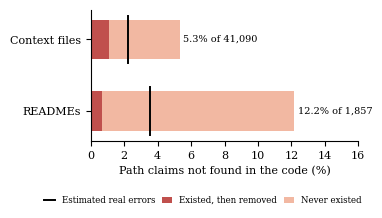

In [13]:
ds, labs = ['context_file', 'readme'], ['Context files', 'READMEs']
stale = [comp.get((d, 'stale_unfixed'), 0) / N['claims'][d] * 100 for d in ds]
never = [comp.get((d, 'never_valid'), 0) / N['claims'][d] * 100 for d in ds]
fig, ax = plt.subplots(figsize=(FIG_W, 1.7)); y = np.arange(2)
ax.barh(y, stale, height=.55, color='#c0504d', label='Existed, then removed')
ax.barh(y, never, height=.55, left=stale, color='#f2b8a2', label='Never existed')
for i, d in enumerate(ds):
    ax.plot([est[d]['estimate'] * 100] * 2, [i - .33, i + .33], color='k', lw=1.4, label='Estimated real errors' if i == 0 else None)
    ax.text(stale[i] + never[i] + .2, i, f"{N['missing_rate'][d]*100:.1f}% of {N['claims'][d]:,}", va='center', fontsize=7)
ax.set_yticks(y); ax.set_yticklabels(labs); ax.invert_yaxis(); ax.set_xlim(0, 16); ax.set_xlabel('Path claims not found in the code (%)')
ax.legend(fontsize=6.2, frameon=False, loc='upper center', bbox_to_anchor=(0.42, -0.36), ncol=3, handlelength=1.2, columnspacing=.8)
plt.savefig(f'{FIGS}/rq1.pdf', bbox_inches='tight'); plt.show()

In [14]:
N['precision'] = prec
save_numbers('rq1_numbers', N); print('saved results/rq1_numbers.json')

saved results/rq1_numbers.json
